### Adverse Event Prediction — Steps

1. Target inspection: Check `Adverse_Event` values, missing values, and class balance.
2. EDA: Analyze numerical and categorical variables against the target using charts.
3. Association analysis: Correlation heatmap, categorical association heatmap, and statistical tests.
4. Data preparation: Select features, prevent target leakage, impute missing values, and encode categorical variables.
5. Train/test split: Split data before fitting preprocessing steps.
6. Model training: Dummy Classifier, Logistic Regression, Random Forest, and boosting models.
7. Model evaluation: Confusion matrix, precision, recall, F1-score, ROC-AUC, and PR-AUC.
8. Interpretation: Compare models and identify important predictors.

In [653]:
import pandas as pd
df_cleaned = pd.read_csv("Clinical_data_cleaned.csv")
print(df_cleaned.shape)

/var/folders/cq/c95gl99s7p18x4zp2w401t7h0000gn/T/ipykernel_34730/3077633035.py:2: DtypeWarning: Columns (0: Duration_Days) have mixed types. Specify dtype option on import or set low_memory=False.
  df_cleaned = pd.read_csv("Clinical_data_cleaned.csv")


(1081612, 34)


In [654]:
df_cleaned.columns.tolist()
len(df_cleaned)
df_cleaned.columns.tolist()

['Patient_ID',
 'patient_id',
 'Age',
 'Gender',
 'Ethnicity',
 'Weight_kg',
 'Weight_lbs',
 'Height_cm',
 'BMI',
 'blood_pressure',
 'Systolic_BP',
 'Diastolic_BP',
 'Heart_Rate',
 'Temperature_F',
 'Hemoglobin',
 'WBC_Count',
 'ALT_Enzyme',
 'AST_Enzyme',
 'Creatinine',
 'eGFR',
 'HbA1c',
 'Total_Cholesterol',
 'Drug_Name',
 'Dosage',
 'Duration_Days',
 'Route',
 'Concurrent_Drugs',
 'Diagnosis',
 'Smoking_Status',
 'Alcohol_Use',
 'Admission_Date',
 'Treatment_Outcome',
 'Adverse_Event',
 'Readmission_30d']

Your columns can be divided into three groups. Since `Treatment_Outcome` and `Adverse_Event` are your two target variables, keep them separate from the predictor features.

## 1. Target variables (2)

- `Treatment_Outcome`
- `Adverse_Event`

## 2. Categorical variables (9)

- `Gender`
- `Ethnicity`
- `Drug_Name`
- `Route`
- `Diagnosis`
- `Smoking_Status`
- `Alcohol_Use`
- `Treatment_Outcome`
- `Adverse_Event`

## 3. Numerical variables (22)

- `Age`
- `Weight_kg`
- `Weight_lbs`
- `Height_cm`
- `BMI`
- `blood_pressure`
- `Systolic_BP`
- `Diastolic_BP`
- `Heart_Rate`
- `Temperature_F`
- `Hemoglobin`
- `WBC_Count`
- `ALT_Enzyme`
- `AST_Enzyme`
- `Creatinine`
- `eGFR`
- `HbA1c`
- `Total_Cholesterol`
- `Dosage`
- `Duration_Days`
- `Concurrent_Drugs`
- `Readmission_30d`

## 4. Date variable (1)

\- `Admission_Date`

## 5. Identifier variables (2 — exclude from predictors)

- `Patient_ID`
- `patient_id`



Step1. Target inspection

In [655]:
# Adverse_Event — target inspection

print("Data type:", df_clean["Adverse_Event"].dtype)
print("\nMissing values:", df_clean["Adverse_Event"].isna().sum())
print("\nValue counts:")
print(df_clean["Adverse_Event"].value_counts(dropna=False))

Data type: float64

Missing values: 86980

Value counts:
Adverse_Event
0.0    745309
1.0    249323
NaN     86980
Name: count, dtype: int64


In [656]:
# Adverse_Event — class distribution

counts = df_clean["Adverse_Event"].value_counts()

print("Class percentages (excluding missing labels):")
print((counts / counts.sum() * 100).round(2))

Class percentages (excluding missing labels):
Adverse_Event
0.0    74.93
1.0    25.07
Name: count, dtype: float64


Step 1 complete — Target distribution
- Class 0: 74.93% (no adverse event)
- Class 1: 25.07% (adverse event)
- Missing labels: 86,980 (8.04% of all rows)
The target classes are moderately imbalanced. We’ll account for this when evaluating models; we don’t need to rebalance the data at this stage.

In [657]:
# Create a dataset containing rows with known target labels
df_model = df_clean[df_clean["Adverse_Event"].notna()].copy()

print("Modelling dataset shape:", df_model.shape)

Modelling dataset shape: (994632, 34)


Modeling Dataset Preparation: Created df_model from df_clean by retaining only records with a known Adverse_Event target label.

Step2: EDA
Numerical variables vs. Adverse_Event
compare numerical variables between patients with and without an adverse event using box plots.

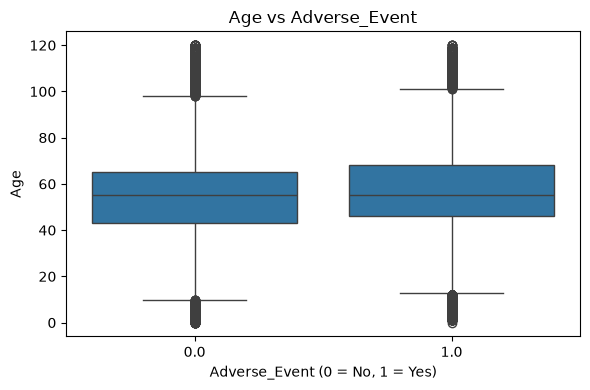

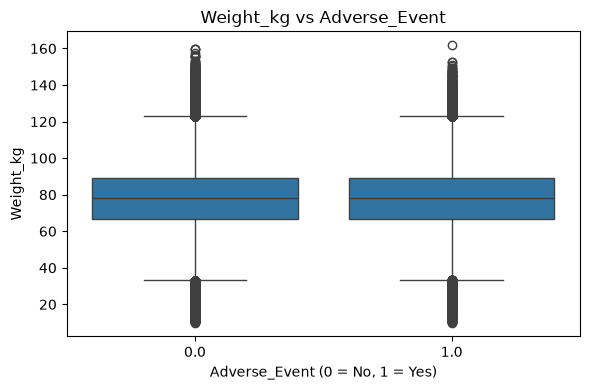

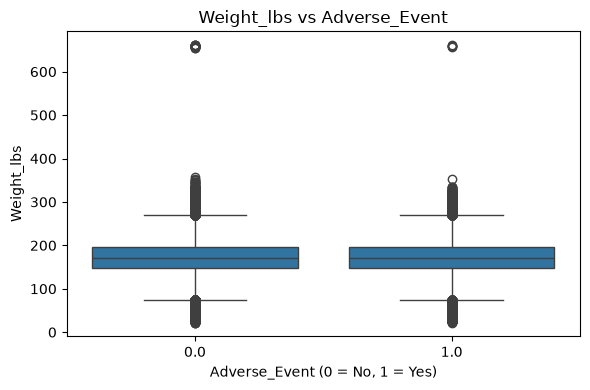

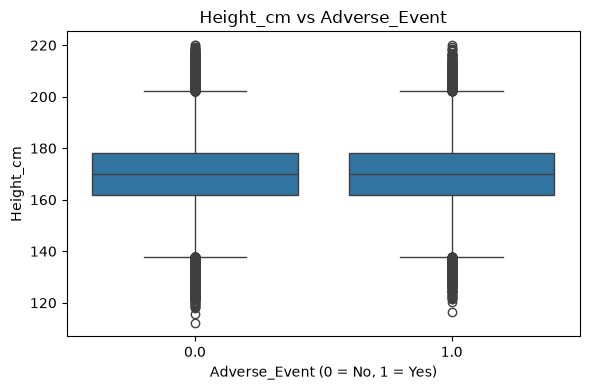

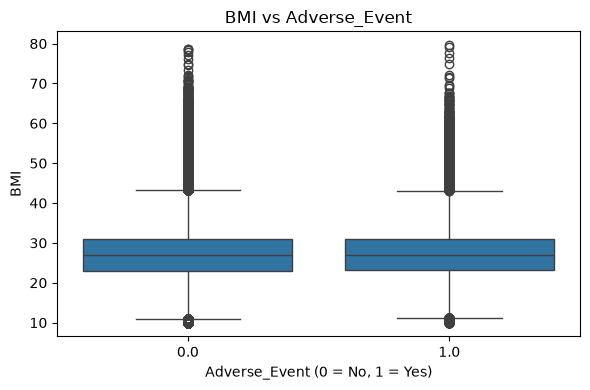

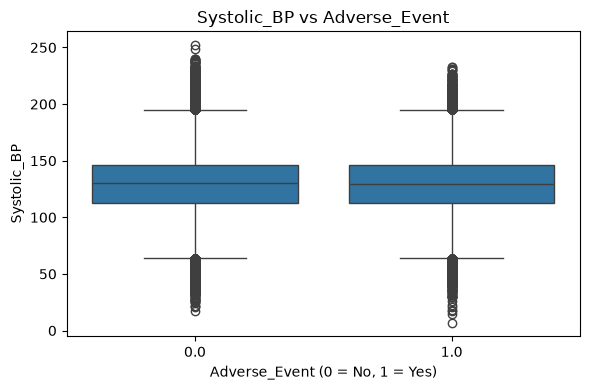

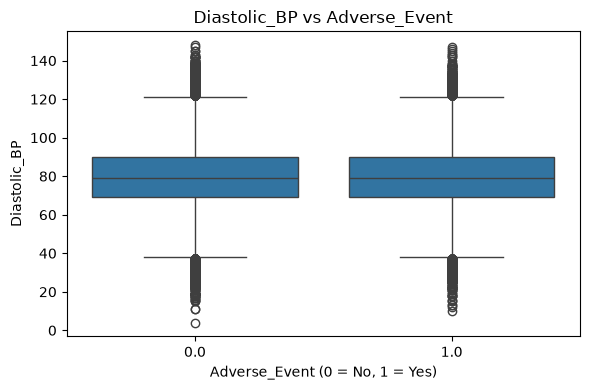

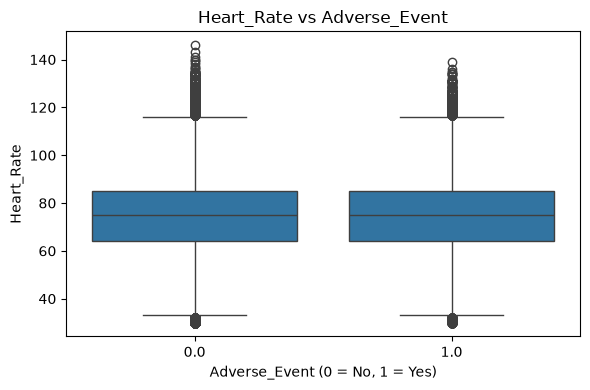

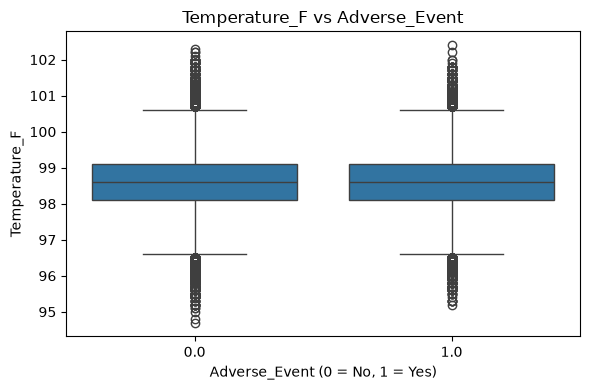

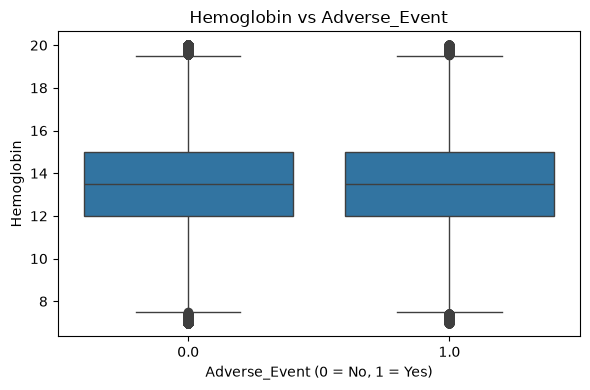

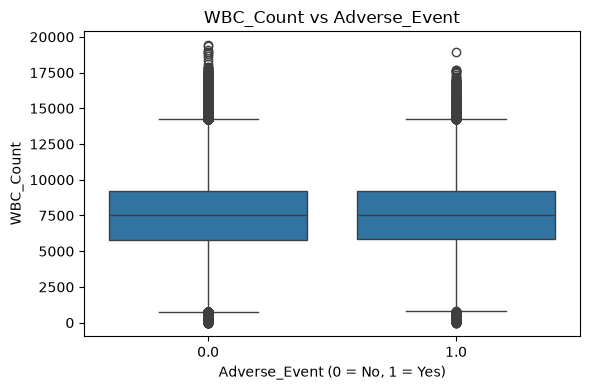

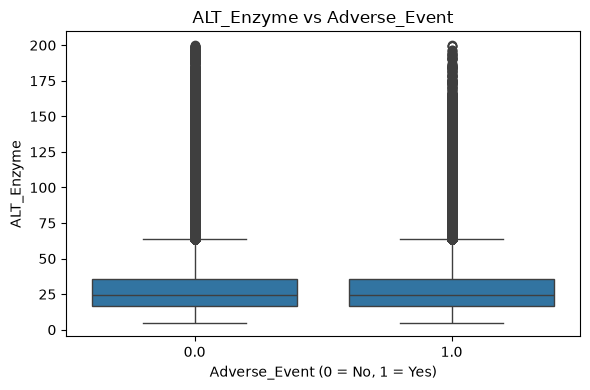

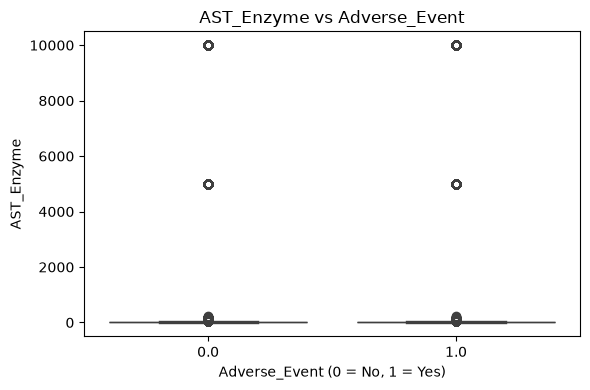

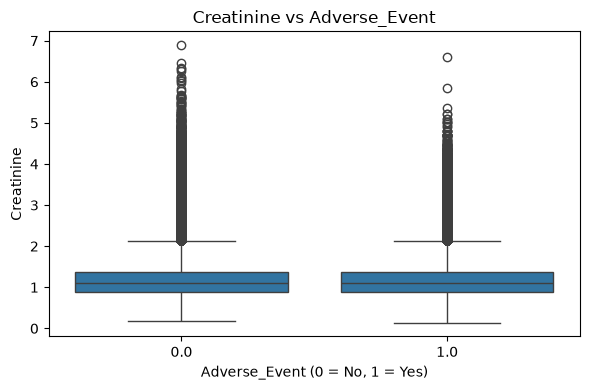

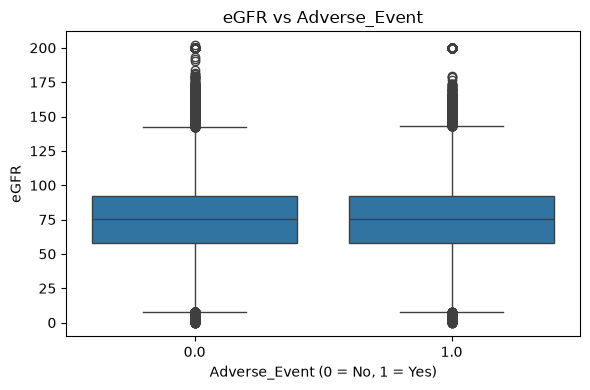

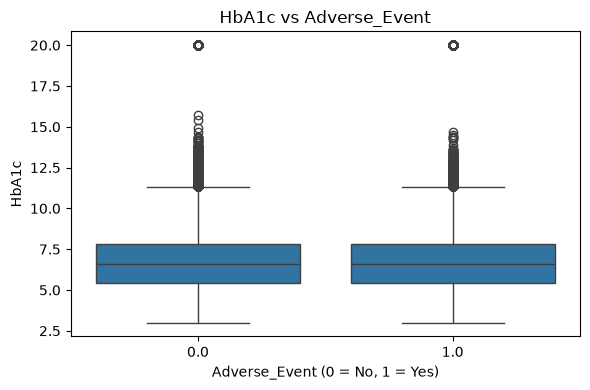

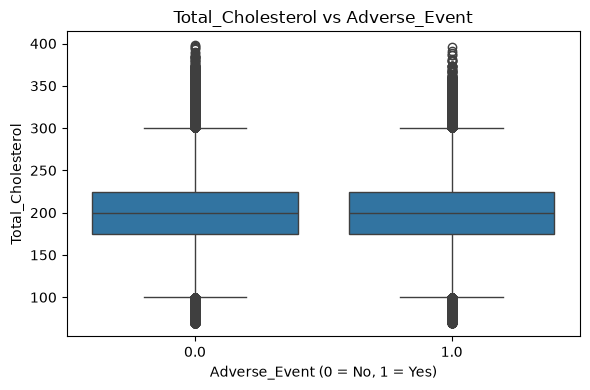

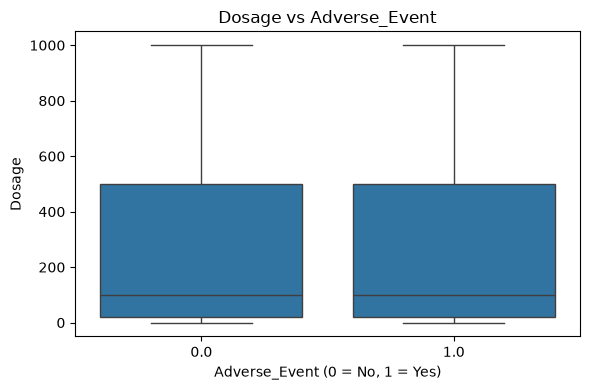

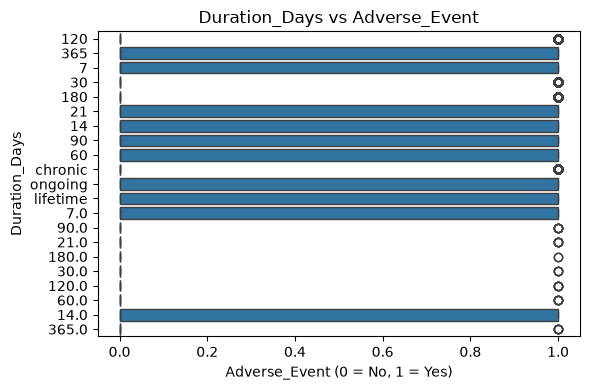

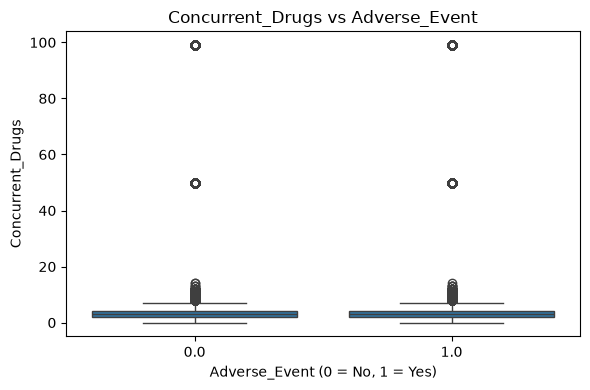

In [658]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_features = [
    "Age", "Weight_kg", "Weight_lbs", "Height_cm", "BMI",
    "Systolic_BP", "Diastolic_BP", "Heart_Rate", "Temperature_F",
    "Hemoglobin", "WBC_Count", "ALT_Enzyme", "AST_Enzyme",
    "Creatinine", "eGFR", "HbA1c", "Total_Cholesterol",
    "Dosage", "Duration_Days", "Concurrent_Drugs"
]

df_plot = df_clean.dropna(subset=["Adverse_Event"])

for col in numerical_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df_plot, x="Adverse_Event", y=col)
    plt.title(f"{col} vs Adverse_Event")
    plt.xlabel("Adverse_Event (0 = No, 1 = Yes)")
    plt.tight_layout()
    plt.show()

Box plots showed no obvious visual differences in the distributions of numerical variables between patients with and without adverse events. Median comparisons are needed to identify potential differences. Similar-looking box plots do not necessarily mean there is no association.

In [659]:
# Check data types of the selected numerical features
print(df_clean[numerical_features].dtypes)

Age                  float64
Weight_kg            float64
Weight_lbs           float64
Height_cm            float64
BMI                  float64
Systolic_BP          float64
Diastolic_BP         float64
Heart_Rate           float64
Temperature_F        float64
Hemoglobin           float64
WBC_Count            float64
ALT_Enzyme           float64
AST_Enzyme           float64
Creatinine           float64
eGFR                 float64
HbA1c                float64
Total_Cholesterol    float64
Dosage               float64
Duration_Days         object
Concurrent_Drugs     float64
dtype: object


In [660]:
exclude_cols = ["Patient_ID", "patient_id", "Adverse_Event", "Readmission_30d"]

numeric_cols = [
    col for col in df_clean.select_dtypes(include="number").columns
    if col not in exclude_cols
]

print(numeric_cols)

['Age', 'Weight_kg', 'Weight_lbs', 'Height_cm', 'BMI', 'Systolic_BP', 'Diastolic_BP', 'Heart_Rate', 'Temperature_F', 'Hemoglobin', 'WBC_Count', 'ALT_Enzyme', 'AST_Enzyme', 'Creatinine', 'eGFR', 'HbA1c', 'Total_Cholesterol', 'Dosage', 'Concurrent_Drugs']


compare the median of each numerical feature between patients with and without adverse events.
How to interpret the output:
- No_Adverse_Event: median for patients with target 0.
- Adverse_Event: median for patients with target 1.
- Median_Difference: median in group 1 minus median in group 0.
- Positive difference: the median is higher in the adverse-event group.
- Negative difference: the median is lower in the adverse-event group.
This identifies potential differences that may not be obvious in boxplots. Median differences alone do not establish statistical significance;

In [661]:
median_comparison = (
    df_clean[df_clean["Adverse_Event"].isin([0, 1])]
    .groupby("Adverse_Event")[numeric_cols]
    .median()
    .T
)

median_comparison.columns = ["No_Adverse_Event", "Adverse_Event"]

median_comparison["Median_Difference"] = (
    median_comparison["Adverse_Event"]
    - median_comparison["No_Adverse_Event"]
)

median_comparison

,No_Adverse_Event,Adverse_Event,Median_Difference
Age,55.000000,55.000000,0.0
Weight_kg,78.000000,78.000000,0.0
Weight_lbs,172.031293,172.031293,0.0
Height_cm,170.000000,170.000000,0.0
BMI,26.900000,26.900000,0.0
Systolic_BP,130.000000,129.000000,-1.0
Diastolic_BP,79.000000,79.000000,0.0
Heart_Rate,75.000000,75.000000,0.0
Temperature_F,98.600000,98.600000,0.0
Hemoglobin,13.500000,13.500000,0.0


**Median Comparison – Adverse Event**

- 17 of 19 numerical features had identical medians across both groups.
- `Systolic_BP`: 130 (no event) vs. 129 (event).
- `WBC_Count`: 7,501 (no event) vs. 7,506 (event).
- Median differences were minimal; identical medians do not rule out associations.

In [662]:
categorical_cols = df_clean.select_dtypes(
    include=["object", "category"]
).columns.tolist()

categorical_cols

/var/folders/cq/c95gl99s7p18x4zp2w401t7h0000gn/T/ipykernel_34730/178240136.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_clean.select_dtypes(


['Gender',
 'Ethnicity',
 'blood_pressure',
 'Drug_Name',
 'Duration_Days',
 'Route',
 'Diagnosis',
 'Smoking_Status',
 'Alcohol_Use',
 'Admission_Date',
 'Treatment_Outcome']

Modeling Dataset Preparation: Created df_model from df_clean by retaining only records with a known Adverse_Event target label.

In [663]:
categorical_cols = [
    col for col in df_model.select_dtypes(include=["object", "category"]).columns
    if col != "Duration_Days"
]

print(categorical_cols)

['Gender', 'Ethnicity', 'blood_pressure', 'Drug_Name', 'Route', 'Diagnosis', 'Smoking_Status', 'Alcohol_Use', 'Admission_Date', 'Treatment_Outcome']


/var/folders/cq/c95gl99s7p18x4zp2w401t7h0000gn/T/ipykernel_34730/2282246649.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  col for col in df_model.select_dtypes(include=["object", "category"]).columns


In [664]:
categorical_cols = [
    col for col in df_model.select_dtypes(
        include=["object", "category", "str"]
    ).columns
    if col not in ["Duration_Days", "Admission_Date"]
]

print(categorical_cols)

['Gender', 'Ethnicity', 'blood_pressure', 'Drug_Name', 'Route', 'Diagnosis', 'Smoking_Status', 'Alcohol_Use', 'Treatment_Outcome']


In [665]:
import pandas as pd

category_rates = {}

for col in categorical_cols:
    category_rates[col] = (
        df_model.groupby(col, dropna=False)["Adverse_Event"]
        .agg(["count", "mean"])
        .rename(columns={"count": "Count", "mean": "Adverse_Event_Rate"})
        .assign(
            Adverse_Event_Rate=lambda x: x["Adverse_Event_Rate"] * 100
        )
        .sort_values("Adverse_Event_Rate", ascending=False)
    )

category_rates["Gender"]

,Count,Adverse_Event_Rate
Gender,,
NaN,395379,25.155104
Female,246756,25.127251
Other,105495,25.069435
Male,247002,24.864171


In [666]:
import pandas as pd

category_rates = {}

for col in categorical_cols:
    category_rates[col] = (
        df_model.groupby(col, dropna=False)["Adverse_Event"]
        .agg(["count", "mean"])
        .rename(columns={"count": "Count", "mean": "Adverse_Event_Rate"})
        .assign(
            Adverse_Event_Rate=lambda x: x["Adverse_Event_Rate"] * 100
        )
        .sort_values("Adverse_Event_Rate", ascending=False)
    )

category_rates["Drug_Name"]

,Count,Adverse_Event_Rate
Drug_Name,,
prednisone,12232,26.299869
clopidogrel,12297,25.859966
levothyroxine,12363,25.641026
warfarin,61573,25.504685
sertraline,12055,25.491497
losartan,12119,25.464147
ciprofloxacin,12324,25.446284
simvastatin,12158,25.324889
rosuvastatin,12211,25.272295


In [667]:
import pandas as pd

category_rates = {}

for col in categorical_cols:
    category_rates[col] = (
        df_model.groupby(col, dropna=False)["Adverse_Event"]
        .agg(["count", "mean"])
        .rename(columns={"count": "Count", "mean": "Adverse_Event_Rate"})
        .assign(
            Adverse_Event_Rate=lambda x: x["Adverse_Event_Rate"] * 100
        )
        .sort_values("Adverse_Event_Rate", ascending=False)
    )

category_rates["Ethnicity"]

,Count,Adverse_Event_Rate
Ethnicity,,
Black,54480,25.559838
Pacific Islander,27371,25.322422
Other,54137,25.219351
White,136634,25.195779
Unknown,257012,25.139293
Prefer not to say,27146,25.049731
Mixed,26954,24.979595
Hispanic,136953,24.959658
Asian,136916,24.859768


KeyboardInterrupt: 

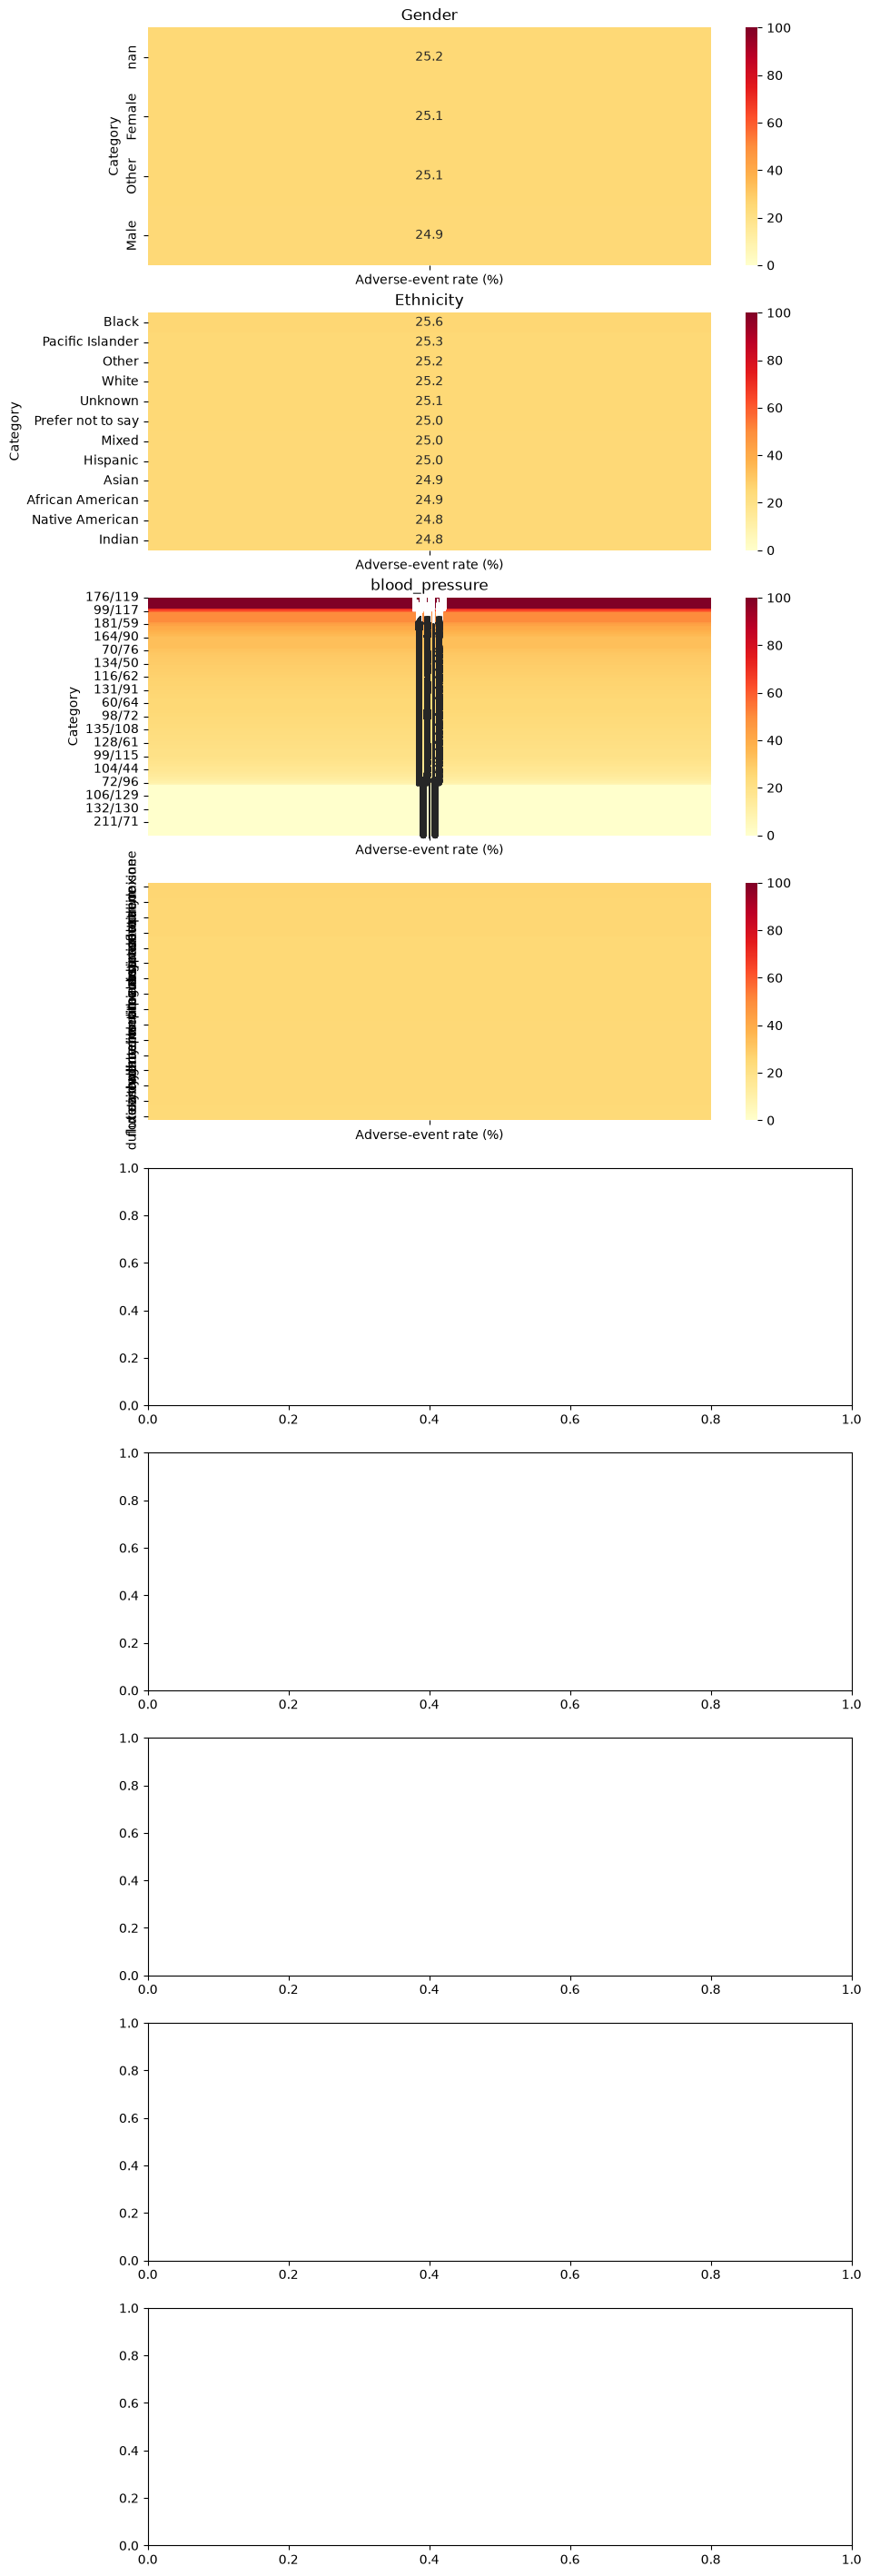

In [668]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Exclude date and columns reserved for separate cleaning
eda_categorical_cols = [
    col for col in categorical_cols
    if col not in ["Admission_Date", "Duration_Days"]
]

fig, axes = plt.subplots(
    len(eda_categorical_cols), 1,
    figsize=(10, 4 * len(eda_categorical_cols))
)

for ax, col in zip(axes, eda_categorical_cols):
    rates = (
        df_model.groupby(col, dropna=False)["Adverse_Event"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    sns.heatmap(
        rates.to_frame(name="Adverse-event rate (%)"),
        annot=True,
        fmt=".1f",
        cmap="YlOrRd",
        vmin=0,
        vmax=100,
        ax=ax
    )
    ax.set_title(col)
    ax.set_ylabel("Category")
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

This code completes your categorical feature heatmap analysis. It calculates the adverse-event rate for each category and displays the rates as heatmaps.

In [ ]:
print("Target: Adverse_Event")
print("Categorical features:", categorical_cols)
print("Numerical features:", numeric_cols)

Target: Adverse_Event
Categorical features: ['Gender', 'Ethnicity', 'blood_pressure', 'Drug_Name', 'Route', 'Diagnosis', 'Smoking_Status', 'Alcohol_Use', 'Treatment_Outcome']
Numerical features: ['Age', 'Weight_kg', 'Weight_lbs', 'Height_cm', 'BMI', 'Systolic_BP', 'Diastolic_BP', 'Heart_Rate', 'Temperature_F', 'Hemoglobin', 'WBC_Count', 'ALT_Enzyme', 'AST_Enzyme', 'Creatinine', 'eGFR', 'HbA1c', 'Total_Cholesterol', 'Dosage', 'Concurrent_Drugs']


In [ ]:
target_col = "Adverse_Event"

categorical_cols = [
    "Gender", "Ethnicity", "blood_pressure", "Drug_Name",
    "Route", "Diagnosis", "Smoking_Status", "Alcohol_Use",
    "Treatment_Outcome"
]

Step4: Feature Selection

**Target:** `Adverse_Event` (0 = No, 1 = Yes). Rows with missing target values will be excluded from model training.

**Categorical features (9):** Gender, Ethnicity, blood_pressure, Drug_Name, Route, Diagnosis, Smoking_Status, Alcohol_Use, Treatment_Outcome.

**Numerical features (19):** Age, Weight_kg, Weight_lbs, Height_cm, BMI, Systolic_BP, Diastolic_BP, Heart_Rate, Temperature_F, Hemoglobin, WBC_Count, ALT_Enzyme, AST_Enzyme, Creatinine, eGFR, HbA1c, Total_Cholesterol, Dosage, Concurrent_Drugs.

**Rationale:** Features represent patient demographics, medical conditions, clinical measurements, and medication-related factors potentially associated with adverse events.

**Considerations:** Investigate potential leakage from `Treatment_Outcome` and redundancy among weight, height, and BMI. Handle missing predictor values during preprocessing.

**Next step:** Stratified train/test split and preprocessing.

In [ ]:
# Exclude rows with missing target
df_model = df_model[df_model["Adverse_Event"].notna()].copy()

# Define predictors and target
X = df_model[categorical_cols + numeric_cols].copy()
y = df_model["Adverse_Event"].astype(int)

print("Feature matrix:", X.shape)
print("Target:", y.shape)

Feature matrix: (994632, 28)
Target: (994632,)


Step 5: Train/test split
Now we split the selected dataset into training and testing sets before preprocessing or model training.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (795705, 28)
X_test: (198927, 28)
y_train: (795705,)
y_test: (198927,)


Step 6 — Preprocessing
We need to handle missing values and encode categorical variables before training the model. We'll use a ColumnTransformer and Pipeline so preprocessing is fitted only on the training data, preventing data leakage.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (795705, 15120)
Processed test shape: (198927, 15120)


Your preprocessing completed successfully.
- Training data: 795,705 rows × 15,120 features
- Test data: 198,927 rows × 15,120 features
The increase from 28 to 15,120 features is due to one-hot encoding of categorical variables, likely with many distinct Drug_Name and other category values.

Step 7 — Train a baseline model
Start with Logistic Regression to establish a baseline for predicting Adverse_Event.

### Why We Used Logistic Regression Instead of Linear Regression

Because our target, `Adverse_Event`, is a binary variable (0 = no adverse event, 1 = adverse event), we started with **Logistic Regression**, not Linear Regression.

**Linear Regression**
- Used for continuous numerical targets.
- Predicts values such as a patient's temperature, weight, or cholesterol level.

**Logistic Regression**
- Used for classification tasks.
- Estimates the probability of an adverse event between 0 and 1 and predicts class 0 or 1 using a threshold.

Linear Regression can produce predictions outside the 0–1 range, making it less suitable for binary classification. Logistic Regression is designed for this task.

**For our project:** Logistic Regression was the appropriate baseline model. However, the ROC-AUC of `0.5411` indicates weak predictive performance, so we should investigate the features and compare other classification models.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_processed, y_train)

y_pred = model.predict(X_test_processed)
y_prob = model.predict_proba(X_test_processed)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.55      0.64    149062
           1       0.27      0.51      0.36     49865

    accuracy                           0.54    198927
   macro avg       0.52      0.53      0.50    198927
weighted avg       0.65      0.54      0.57    198927

Confusion Matrix:
[[81820 67242]
 [24453 25412]]
ROC-AUC: 0.5411


### Logistic Regression — Model Evaluation

- **Accuracy (54%)**: The model correctly predicts about 54% of outcomes.
- **Precision (Class 1: 27%)**: Many predicted adverse events are false positives.
- **Recall (Class 1: 51%)**: The model detects 51% of actual adverse events and misses 49%.
- **F1-score (Class 1: 0.36)**: Weak balance between precision and recall.
- **ROC-AUC (0.5411)**: The model has poor ability to distinguish between patients with and without adverse events.

**Conclusion:** The baseline model has weak predictive performance. Compare other classification models and evaluate whether they improve adverse-event detection and reduce false positives.

In [ ]:
print("Current X_train:", X_train.shape)
print("Model features:", getattr(model, "n_features_in_", "Unknown"))
print("Model trained:", hasattr(model, "coef_"))

Current X_train: (795705, 28)
Model features: 15120
Model trained: True


In [ ]:
%whos

Variable                  Type                      Data/Info
-------------------------------------------------------------
ColumnTransformer         ABCMeta                   <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
LogisticRegression        type                      <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
OneHotEncoder             type                      <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
Pipeline                  ABCMeta                   <class 'sklearn.pipeline.Pipeline'>
RandomForestClassifier    ABCMeta                   <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
SimpleImputer             type                      <class 'sklearn.impute._base.SimpleImputer'>
StandardScaler            type                      <class 'sklearn.preproces<...>ng._data.StandardScaler'>
X                         DataFrame                 Shape: (994632, 28)
X_test                    DataFrame                 Shape: (198927, 28)
X_test_

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

Python(50869) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [669]:
y_pred_rf = rf_model.predict(X_test_processed)
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

Classification Report:
              precision    recall  f1-score   support

           0       0.76      1.00      0.86    149062
           1       1.00      0.05      0.09     49865

    accuracy                           0.76    198927
   macro avg       0.88      0.52      0.48    198927
weighted avg       0.82      0.76      0.67    198927

Confusion Matrix:
[[149061      1]
 [ 47569   2296]]
ROC-AUC: 0.581268591517151


 ## Random Forest – Model Evaluation

**ROC-AUC:** 0.5813

### Classification Results

| Metric | Class 0 | Class 1 |
|---|---:|---:|
| Precision | 0.76 | 1.00 |
| Recall | 1.00 | 0.05 |
| F1-score | 0.86 | 0.09 |
| Support | 149,062 | 49,865 |

### Confusion Matrix

`[[149061, 1], [47569, 2296]]`

- **True Negatives (TN):** 149,061
- **False Positives (FP):** 1
- **False Negatives (FN):** 47,569
- **True Positives (TP):** 2,296

### Interpretation

- The model correctly identifies almost all patients without adverse events.
- Class 1 precision is 100%, meaning almost all predicted adverse events are genuine in this test set.
- Class 1 recall is only 5%, meaning the model detects only about 5% of actual adverse events.
- ROC-AUC of 0.5813 indicates weak ability to distinguish between the two classes.

### Comparison with Logistic Regression

| Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| Class 1 precision | 0.27 | 1.00 |
| Class 1 recall | 0.51 | 0.05 |
| Class 1 F1-score | 0.36 | 0.09 |
| ROC-AUC | 0.5411 | 0.5813 |

Random Forest has a higher ROC-AUC, but Logistic Regression detects substantially more adverse events at the default classification threshold.

### Next Step

Evaluate different probability thresholds to determine whether Random Forest can improve adverse-event recall while maintaining acceptable precision.

In [670]:
print(model.class_weight)

balanced


In [671]:
from sklearn.ensemble import RandomForestClassifier

rf_model_balanced = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model_balanced.fit(X_train_processed, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [673]:
y_pred_rf_balanced = rf_model_balanced.predict(X_test_processed)
y_prob_rf_balanced = rf_model_balanced.predict_proba(X_test_processed)[:, 1]

In [674]:
print("Balanced Random Forest - Classification Report:")
print(classification_report(y_test, y_pred_rf_balanced))

print("Balanced Random Forest - Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_balanced))

print("Balanced Random Forest - ROC-AUC:",
      roc_auc_score(y_test, y_prob_rf_balanced))

Balanced Random Forest - Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.98      0.86    149062
           1       0.58      0.07      0.13     49865

    accuracy                           0.75    198927
   macro avg       0.67      0.53      0.49    198927
weighted avg       0.71      0.75      0.67    198927

Balanced Random Forest - Confusion Matrix:
[[146501   2561]
 [ 46325   3540]]
Balanced Random Forest - ROC-AUC: 0.5878779597346858


### Random Forest – Class Weighting Comparison

Using `class_weight='balanced'` increased class 1 recall from **5% to 7%** and F1-score from **0.09 to 0.13**. ROC-AUC improved slightly from **0.5813 to 0.5879**, while precision decreased from 100% to 58%.

**Conclusion:** Class weighting produced modest improvement, but adverse-event detection remains poor. Further model comparison and threshold evaluation are needed.

### Random Forest – Class Weighting

The first Random Forest achieved only **5% recall** for adverse events. A second model uses `class_weight='balanced'` to give more importance to the minority class during training.

**Objective:** Compare both models using the same data and metrics to assess whether class weighting improves adverse-event detection without changing the dataset.

Next model : Catboost

In [676]:
%pip install catboost
import catboost
print(catboost.__version__)

Python(52298) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


  Using cached catboost-1.2.10-cp314-cp314-macosx_11_0_universal2.whl.metadata (1.4 kB)
  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
Using cached catboost-1.2.10-cp314-cp314-macosx_11_0_universal2.whl (28.8 MB)
Using cached graphviz-0.21-py3-none-any.whl (47 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 5.1 MB/s  0:00:01 eta 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [catboost]2/3 [catboost]

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
1.2.10


In [678]:
X_train_cat = X_train.copy()
X_test_cat = X_test.copy()

cat_features = X_train_cat.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for col in cat_features:
    X_train_cat[col] = X_train_cat[col].fillna("Missing").astype(str)
    X_test_cat[col] = X_test_cat[col].fillna("Missing").astype(str)

In [681]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = weights.tolist()
print(class_weights)

[0.667261218924372, 1.994668050416629]


In [682]:
cat_model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.1,
    depth=6,
    random_seed=42,
    verbose=100,
    allow_writing_files=False,
    class_weights=class_weights
)

cat_model.fit(
    X_train_cat,
    y_train,
    cat_features=cat_features
)

0:	learn: 0.6920168	total: 873ms	remaining: 14m 31s
100:	learn: 0.6772561	total: 1m 17s	remaining: 11m 26s
200:	learn: 0.6737352	total: 2m 17s	remaining: 9m 6s
300:	learn: 0.6714585	total: 3m 19s	remaining: 7m 43s
400:	learn: 0.6700187	total: 4m 14s	remaining: 6m 20s
500:	learn: 0.6684325	total: 5m 33s	remaining: 5m 31s
600:	learn: 0.6669470	total: 7m 27s	remaining: 4m 57s
700:	learn: 0.6656265	total: 8m 33s	remaining: 3m 39s
800:	learn: 0.6643841	total: 9m 25s	remaining: 2m 20s
900:	learn: 0.6631668	total: 10m 17s	remaining: 1m 7s
999:	learn: 0.6619647	total: 11m 25s	remaining: 0us


CatBoostClassifier(allow_writing_files=False, class_weights=[0.667261218924372, 1.994668050416629], depth=6, iterations=1000, learning_rate=0.1, random_seed=42, verbose=100)

In [684]:
y_pred_cat = cat_model.predict(X_test_cat).ravel()
y_prob_cat = cat_model.predict_proba(X_test_cat)[:, 1]

print("CatBoost - Classification Report:")
print(classification_report(y_test, y_pred_cat))

print("CatBoost - Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_cat))

print("CatBoost - ROC-AUC:", roc_auc_score(y_test, y_prob_cat))

CatBoost - Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.58      0.67    149062
           1       0.31      0.55      0.39     49865

    accuracy                           0.57    198927
   macro avg       0.55      0.57      0.53    198927
weighted avg       0.67      0.57      0.60    198927

CatBoost - Confusion Matrix:
[[87004 62058]
 [22553 27312]]
CatBoost - ROC-AUC: 0.6023261898779844


### CatBoost — Balanced Model Results

- **Class 1 (Adverse Event):**
  - Precision: 0.31
  - Recall: 0.55
  - F1-score: 0.39
- **Accuracy:** 0.57
- **ROC-AUC:** 0.6023

**Confusion Matrix:**
```text
[[87004 62058]
 [22553 27312]]
```

**Interpretation:**
- Detected 55% of actual adverse events.
- 31% of predicted adverse events were actual adverse events.
- ROC-AUC indicates weak class discrimination.
- Outperformed both Random Forest models in adverse-event recall and F1-score.

**Next step:** Train XGBoost with class weighting using the same train/test split.

XG boost

In [686]:
%pip install xgboost

Python(58572) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


  Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl (2.4 MB)

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [687]:
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

xgb_model.fit(
    X_train_processed,
    y_train,
    sample_weight=sample_weights
)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [688]:
y_pred_xgb = xgb_model.predict(X_test_processed)
y_prob_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]

print("XGBoost - Classification Report:")
print(classification_report(y_test, y_pred_xgb))

print("XGBoost - Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print("XGBoost - ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))

XGBoost - Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.54      0.64    149062
           1       0.29      0.56      0.38     49865

    accuracy                           0.54    198927
   macro avg       0.54      0.55      0.51    198927
weighted avg       0.66      0.54      0.57    198927

XGBoost - Confusion Matrix:
[[80439 68623]
 [22065 27800]]
XGBoost - ROC-AUC: 0.5685542279177057


In [689]:
from sklearn.ensemble import AdaBoostClassifier

print("AdaBoost is ready to use.")

AdaBoost is ready to use.


In [690]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

ada_model = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

ada_model.fit(
    X_train_processed,
    y_train,
    sample_weight=sample_weights
)

,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",0.1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](100,)","[0.46,0.47,0.47,...,0.49,0.49,0.5 ]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](100,)","[0.01,0.01,0.01,...,0. ,0. ,0. ]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1608637542), DecisionTreeC...te=1273642419), DecisionTreeC...te=1935803228), DecisionTreeC...ate=787846414), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](15120,)","[0.5,0. ,0. ,...,0. ,0. ,0. ]"


In [691]:
y_pred_ada = ada_model.predict(X_test_processed)
y_prob_ada = ada_model.predict_proba(X_test_processed)[:, 1]

print("AdaBoost - Classification Report:")
print(classification_report(y_test, y_pred_ada))

print("AdaBoost - Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_ada))

print("AdaBoost - ROC-AUC:", roc_auc_score(y_test, y_prob_ada))

AdaBoost - Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.56      0.65    149062
           1       0.29      0.54      0.38     49865

    accuracy                           0.55    198927
   macro avg       0.54      0.55      0.52    198927
weighted avg       0.66      0.55      0.58    198927

AdaBoost - Confusion Matrix:
[[83361 65701]
 [22980 26885]]
AdaBoost - ROC-AUC: 0.5688017548630445


- **Class 1 (Adverse Event):**
  - Precision: 0.29
  - Recall: 0.54
  - F1-score: 0.38
- **Accuracy:** 0.55
- **ROC-AUC:** 0.5688

**Confusion Matrix:**
```text
[[83361 65701]
 [22980 26885]]
```

**Interpretation:**
- Detected 54% of actual adverse events.
- 29% of predicted adverse events were actual adverse events.
- ROC-AUC indicates weak class discrimination.
- F1-score is similar to XGBoost, but ROC-AUC is slightly higher.

**Current leader:** CatBoost, with class 1 F1-score of 0.39 and ROC-AUC of 0.6023.

**Next step:** Train LightGBM with balanced sample weights.

LightGBM

In [692]:
%pip install lightgbm

Python(58594) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 7.5 MB/s  0:00:00

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [693]:
from lightgbm import LGBMClassifier
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

lgbm_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=-1,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgbm_model.fit(
    X_train_processed,
    y_train,
    sample_weight=sample_weights
)

,n_estimators,300
,random_state,42
,n_jobs,-1
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,subsample_for_bin,200000
,objective,None
,class_weight,None


In [694]:
y_pred_lgbm = lgbm_model.predict(X_test_processed)
y_prob_lgbm = lgbm_model.predict_proba(X_test_processed)[:, 1]

print("LightGBM - Classification Report:")
print(classification_report(y_test, y_pred_lgbm))

print("LightGBM - Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lgbm))

print("LightGBM - ROC-AUC:", roc_auc_score(y_test, y_prob_lgbm))

LightGBM - Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.54      0.64    149062
           1       0.29      0.56      0.38     49865

    accuracy                           0.54    198927
   macro avg       0.54      0.55      0.51    198927
weighted avg       0.66      0.54      0.58    198927

LightGBM - Confusion Matrix:
[[80687 68375]
 [22188 27677]]
LightGBM - ROC-AUC: 0.5675791590643007


### LightGBM — Balanced Model Results

- **Class 1 (Adverse Event):**
  - Precision: 0.29
  - Recall: 0.56
  - F1-score: 0.38
- **Accuracy:** 0.54
- **ROC-AUC:** 0.5676

**Confusion Matrix:**
```text
[[80687 68375]
 [22188 27677]]
```

**Interpretation:**
- Detected 56% of actual adverse events.
- 29% of predicted adverse events were actual adverse events.
- ROC-AUC indicates weak class discrimination.
- F1-score is 0.38, similar to AdaBoost and XGBoost.

**Current leader:** CatBoost, with class 1 F1-score of 0.39 and ROC-AUC of 0.6023.

**Next step:** Compare all models in one summary table before deciding which to tune.

### Model Comparison — Balanced Models

| Model                    | Class 1 Precision | Class 1 Recall | Class 1 F1-score | ROC-AUC |
| ------------------------ | ----------------- | -------------- | ---------------- | ------- |
| Logistic Regression\*    | 0.27              | 0.51           | 0.36             | 0.5411  |
| Random Forest — original | 1.00              | 0.05           | 0.09             | 0.5813  |
| Random Forest — balanced | 0.58              | 0.07           | 0.13             | 0.5879  |
| CatBoost                 | 0.31              | 0.55           | 0.39             | 0.6023  |
| XGBoost                  | 0.29              | 0.56           | 0.38             | 0.5686  |
| AdaBoost                 | 0.29              | 0.54           | 0.38             | 0.5688  |
| LightGBM                 | 0.29              | 0.56           | 0.38             | 0.5676  |

\*Logistic Regression used class weighting. Random Forest original was unweighted; all other listed boosted models used balanced sample weights. The settings are not fully identical across models.

### Conclusion

- Best overall so far: CatBoost — highest class 1 F1-score (0.39) and ROC-AUC (0.6023).
- Highest adverse-event recall among the boosted models: XGBoost and LightGBM (0.56).
- Random Forest: poor adverse-event recall, even with class weighting.

Next step: Tune CatBoost first, then compare its tuned performance with the other promising models. Before selecting a final model, verify that `Treatment_Outcome` is available at the intended prediction time to avoid target leakage.

In [695]:
import joblib
from pathlib import Path

model_dir = Path("saved_models")
model_dir.mkdir(exist_ok=True)

joblib.dump(cat_model, model_dir / "cat_model.pkl")
joblib.dump(xgb_model, model_dir / "xgb_model.pkl")
joblib.dump(ada_model, model_dir / "ada_model.pkl")
joblib.dump(lgbm_model, model_dir / "lgbm_model.pkl")

print("Models saved successfully.")

Models saved successfully.


In [696]:
joblib.dump(preprocessor, model_dir / "preprocessor.pkl")

joblib.dump(
    {
        "X_train_processed": X_train_processed,
        "X_test_processed": X_test_processed,
        "y_train": y_train,
        "y_test": y_test
    },
    model_dir / "data_split.pkl"
)

['saved_models/data_split.pkl']

In [698]:
import joblib
from pathlib import Path

model_dir = Path("saved_models")

cat_model = joblib.load(model_dir / "cat_model.pkl")
xgb_model = joblib.load(model_dir / "xgb_model.pkl")
ada_model = joblib.load(model_dir / "ada_model.pkl")
lgbm_model = joblib.load(model_dir / "lgbm_model.pkl")

preprocessor = joblib.load(model_dir / "preprocessor.pkl")

saved_data = joblib.load(model_dir / "data_split.pkl")

X_train_processed = saved_data["X_train_processed"]
X_test_processed = saved_data["X_test_processed"]
y_train = saved_data["y_train"]
y_test = saved_data["y_test"]

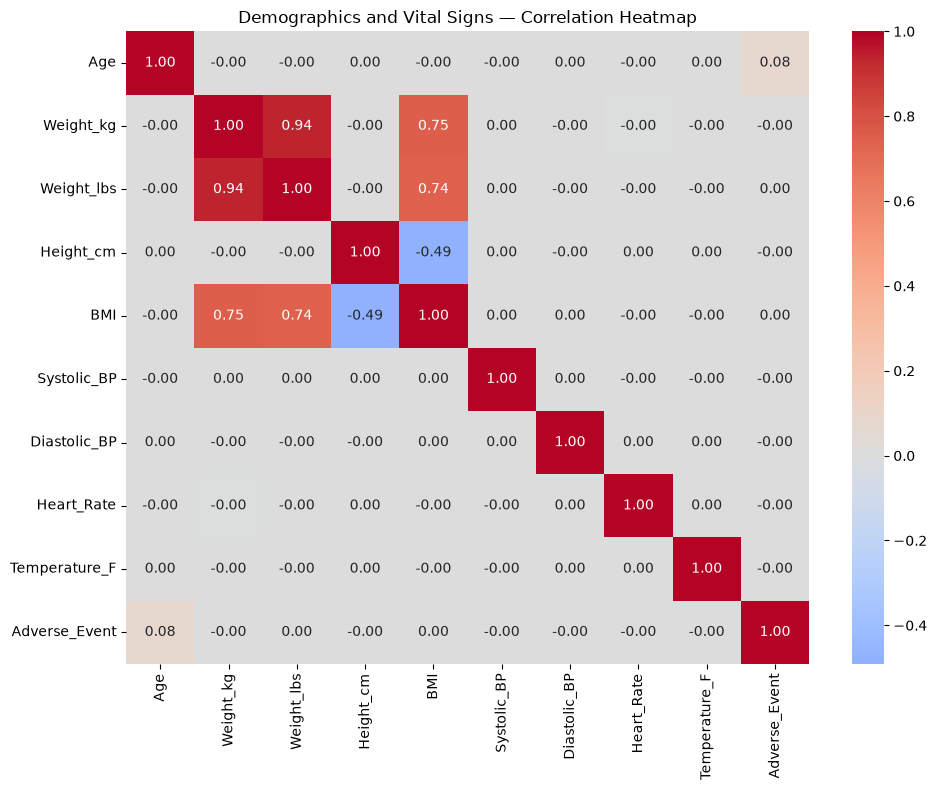

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

demographic_cols = [
    "Age",
    "Weight_kg",
    "Weight_lbs",
    "Height_cm",
    "BMI",
    "Systolic_BP",
    "Diastolic_BP",
    "Heart_Rate",
    "Temperature_F",
    "Adverse_Event"
]

corr_matrix = df_model[demographic_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Demographics and Vital Signs — Correlation Heatmap")
plt.tight_layout()
plt.show()

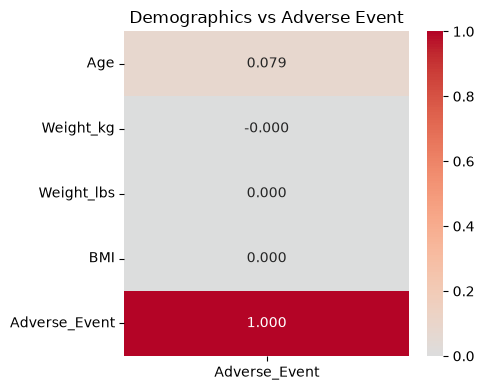

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

demographic_numeric = [
    "Age", "Weight_kg", "Weight_lbs", "BMI"
]

corr = df_model[demographic_numeric + ["Adverse_Event"]].corr()

plt.figure(figsize=(5, 4))
sns.heatmap(corr[["Adverse_Event"]], annot=True, fmt=".3f",
            cmap="coolwarm", center=0)
plt.title("Demographics vs Adverse Event")
plt.tight_layout()
plt.show()

In [ ]:
# Correlation of numeric features with Adverse_Event
target_corr = (
    numeric_df.corr()["Adverse_Event"]
    .drop("Adverse_Event")
    .sort_values(key=abs, ascending=False)
)

print(target_corr.round(3))

Age                  0.079
Concurrent_Drugs     0.046
Readmission_30d      0.001
AST_Enzyme           0.001
WBC_Count            0.001
Heart_Rate          -0.001
Total_Cholesterol   -0.001
Systolic_BP         -0.001
eGFR                 0.001
Height_cm           -0.001
Creatinine          -0.001
ALT_Enzyme          -0.001
Hemoglobin           0.001
Dosage               0.001
Diastolic_BP        -0.000
Weight_lbs           0.000
HbA1c                0.000
Temperature_F       -0.000
BMI                  0.000
Weight_kg           -0.000
Name: Adverse_Event, dtype: float64


In [ ]:
import pandas as pd
from scipy.stats import chi2_contingency

categorical_features = [
    "Drug_Name",
    "Gender",
    "Ethnicity",
    "Diagnosis",
    "Route",
    "Smoking_Status",
    "Alcohol_Use"
]

results = []

for col in categorical_features:
    data = df_model[[col, "Adverse_Event"]].dropna()

    table = pd.crosstab(data[col], data["Adverse_Event"])

    if table.shape[0] < 2 or table.shape[1] < 2:
        continue

    chi2, p_value, _, _ = chi2_contingency(table)

    n = table.to_numpy().sum()
    r, k = table.shape
    cramers_v = (chi2 / (n * min(r - 1, k - 1))) ** 0.5

    results.append({
        "Feature": col,
        "Categories": table.shape[0],
        "Cramers_V": cramers_v,
        "P_Value": p_value
    })

categorical_association = pd.DataFrame(results)
categorical_association.sort_values(
    "Cramers_V", ascending=False
)

,Feature,Categories,Cramers_V,P_Value
0,Drug_Name,30,0.007024,0.054993
3,Diagnosis,20,0.004698,0.535796
2,Ethnicity,12,0.004360,0.062840
1,Gender,3,0.002832,0.090366
4,Route,9,0.002826,0.438910
6,Alcohol_Use,8,0.002664,0.422888
5,Smoking_Status,5,0.001265,0.810418
